In [2]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/simuteh-2330511039/notebook
!ls ..

Mounted at /content/drive
/content/drive/MyDrive/simuteh-2330511039/notebook
data  hasil  laporan  notebook	requirements.txt  src


In [ ]:
# TEPI CANNY

In [3]:
def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

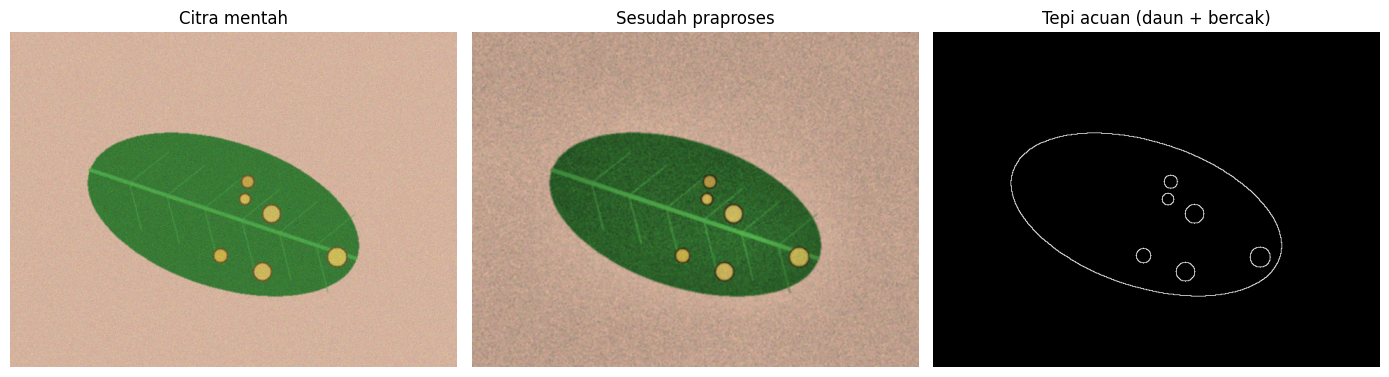

In [4]:
import sys, json
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
PARAM = json.load(open("../hasil/param_praproses.json"))   # hasil Evaluasi P1-P4
label = pd.read_csv("../data/sintetis/label.csv")

def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

img, md, mb = muat("teh_041.png")
pra = praproses(img, PARAM)
acuan = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
tampil([img, pra, acuan], ["Citra mentah", "Sesudah praproses", "Tepi acuan (daun + bercak)"])

In [ ]:
# KODE 3.1

         citra  IoU daun awal  komponen bercak awal  komponen acuan IoU bercak awal
0  teh_041.png          0.994                   233               6           0.451
1  teh_021.png          0.998                   205               2           0.059
2  teh_011.png          0.997                   198               0               -


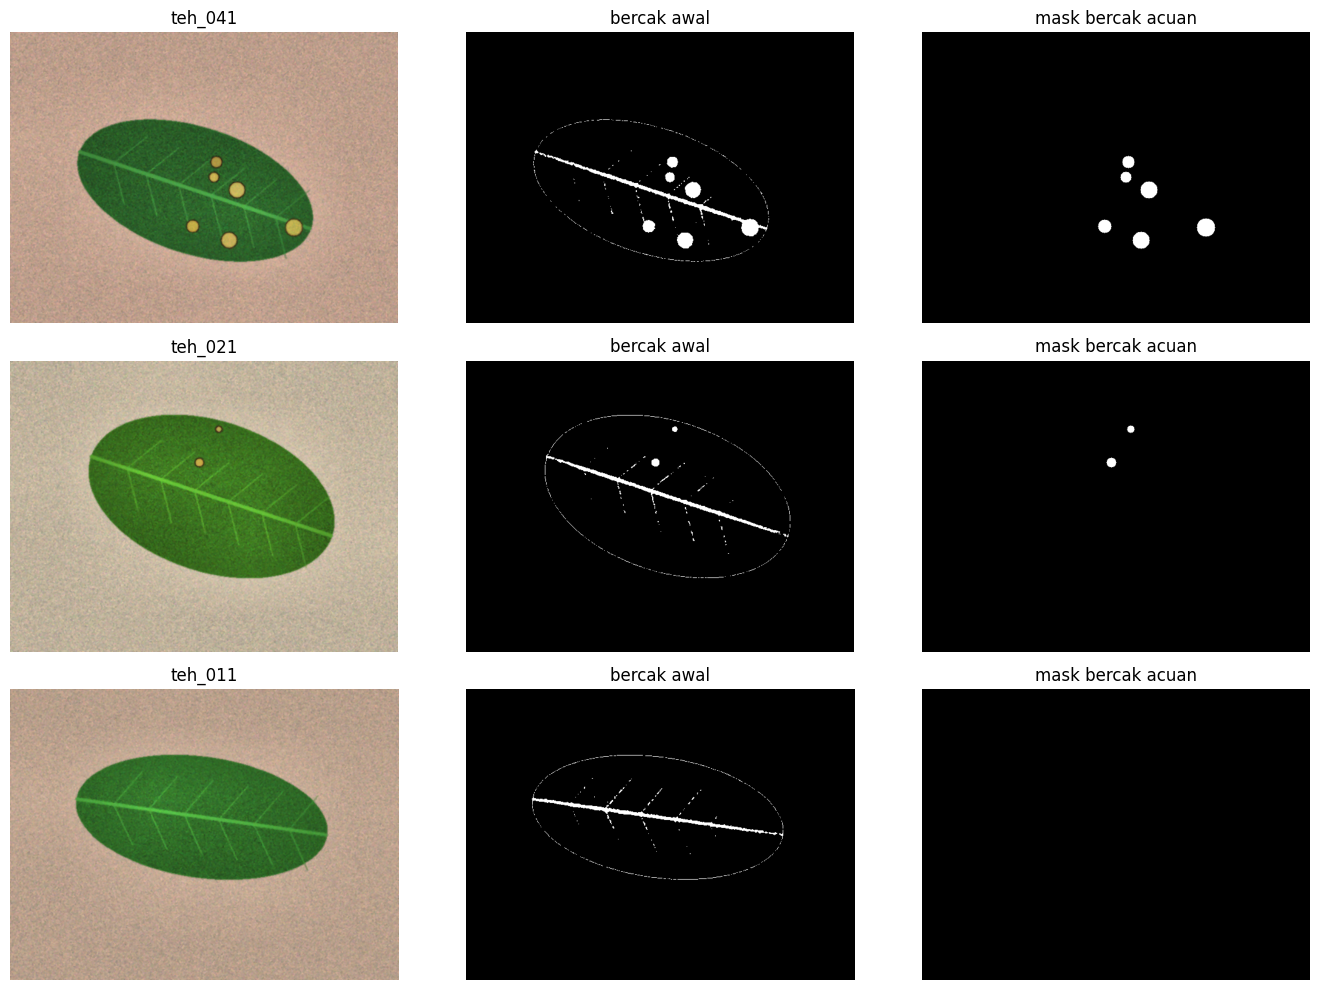

In [5]:
def jumlah_komponen(m, konek=8):
    return cv2.connectedComponents((m > 0).astype(np.uint8), connectivity=konek)[0] - 1

baris, panel, judul = [], [], []
for nama in ["teh_041.png", "teh_021.png", "teh_011.png"]:     # berat, ringan, sehat
    img, md, mb = muat(nama)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    b0 = bercak_awal(pra_, m_daun, kanal=2, k=4.0)
    baris.append([nama, round(iou(m_daun, md), 3), jumlah_komponen(b0), jumlah_komponen(mb),
                  round(iou(b0, mb), 3) if mb.any() else "-"])
    panel += [pra_, b0, mb]; judul += [nama[:7], "bercak awal", "mask bercak acuan"]
print(pd.DataFrame(baris, columns=["citra", "IoU daun awal", "komponen bercak awal",
                                   "komponen acuan", "IoU bercak awal"]))
tampil(panel, judul, baris=3, ukuran=(14, 10))

In [ ]:
# KODE 3.2

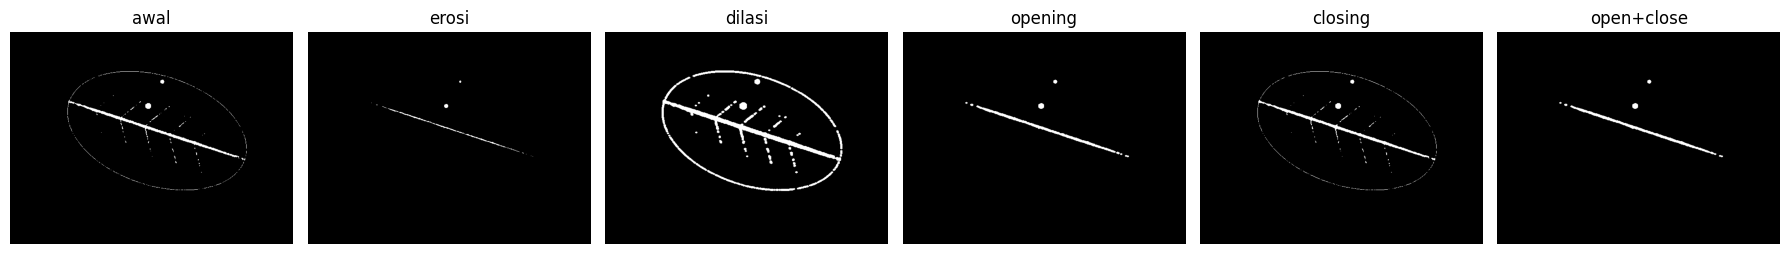

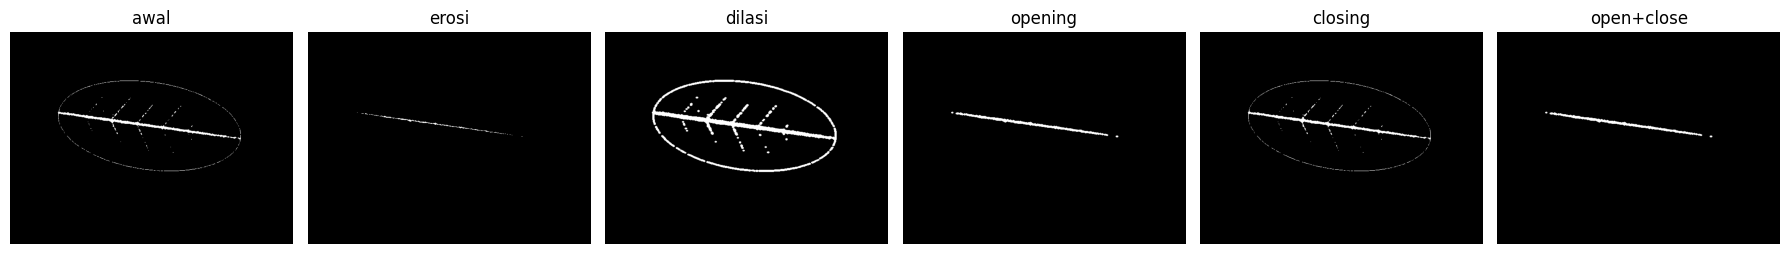

          citra     operasi  komponen  piksel    IoU
0   teh_021.png        awal       205    3421  0.059
1   teh_021.png       erosi        13     737  0.091
2   teh_021.png      dilasi        34   10746  0.029
3   teh_021.png     opening         8    2233  0.086
4   teh_021.png     closing       185    3529  0.057
5   teh_021.png  open+close         6    2250  0.086
6   teh_011.png        awal       198    3084      -
7   teh_011.png       erosi        21     524      -
8   teh_011.png      dilasi        33    9867      -
9   teh_011.png     opening         3    1923      -
10  teh_011.png     closing       178    3175      -
11  teh_011.png  open+close         3    1923      -


In [6]:
SE = lambda k, bentuk=cv2.MORPH_ELLIPSE: cv2.getStructuringElement(bentuk, (k, k))

def operasi(b, se):
    return {"awal": b,
            "erosi": cv2.erode(b, se),
            "dilasi": cv2.dilate(b, se),
            "opening": cv2.morphologyEx(b, cv2.MORPH_OPEN, se),
            "closing": cv2.morphologyEx(b, cv2.MORPH_CLOSE, se),
            "open+close": cv2.morphologyEx(cv2.morphologyEx(b, cv2.MORPH_OPEN, se), cv2.MORPH_CLOSE, se)}

baris = []
for nama in ["teh_021.png", "teh_011.png"]:
    img, md, mb = muat(nama)
    pra_ = praproses(img, PARAM)
    b0 = bercak_awal(pra_, mask_daun_awal(pra_))
    hasil = operasi(b0, SE(5))
    for nm, m in hasil.items():
         baris.append([nama, nm, jumlah_komponen(m), int((m > 0).sum()),
                       round(iou(m, mb), 3) if mb.any() else "-"])
    tampil(list(hasil.values()), list(hasil.keys()), ukuran=(18, 3))
    plt.show()
print(pd.DataFrame(baris, columns=["citra", "operasi", "komponen", "piksel", "IoU"]))


In [ ]:
# KODE 3.3

In [7]:
bentuk = {"persegi": cv2.MORPH_RECT, "elips": cv2.MORPH_ELLIPSE, "silang": cv2.MORPH_CROSS}
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    n_acuan = jumlah_komponen(mb)
    for k in [3, 4, 6]:
        b0 = bercak_awal(pra_, m_daun, k=k)
        for nb, kb in bentuk.items():
            for uk in [3, 5, 7]:
                se = SE(uk, kb)
                m = cv2.morphologyEx(cv2.morphologyEx(b0, cv2.MORPH_OPEN, se), cv2.MORPH_CLOSE, se)
                baris.append([d.kelas, k, nb, uk, abs(jumlah_komponen(m) - n_acuan),
                              iou(m, mb) if mb.any() else np.nan])
eks = pd.DataFrame(baris, columns=["kelas", "k", "bentuk", "ukuran", "galat_jumlah", "IoU"])
print(eks.pivot_table(index=["k", "bentuk", "ukuran"], columns="kelas", values=["galat_jumlah", "IoU"]).round(2))
eks.to_csv("../hasil/p6_eksperimen_se.csv", index=False)

                   IoU        galat_jumlah              
kelas            berat ringan        berat ringan  sehat
k bentuk  ukuran                                        
3 elips   3       0.61   0.13        25.10  47.60  22.10
          5       0.63   0.25         2.50   2.55   4.40
          7       0.66   0.35         1.25   2.55   3.00
  persegi 3       0.62   0.18         7.55  10.05   8.10
          5       0.64   0.28         1.70   3.05   3.85
          7       0.68   0.40         0.95   0.55   0.50
  silang  3       0.61   0.13        25.10  47.60  22.10
          5       0.64   0.23         5.05   5.20   6.35
          7       0.68   0.33         3.30   5.10   6.20
4 elips   3       0.63   0.21        15.30  36.40  16.90
          5       0.64   0.32         2.15   2.15   3.00
          7       0.66   0.41         0.95   1.45   0.85
  persegi 3       0.64   0.24         4.80   8.00   7.30
          5       0.65   0.35         1.45   2.75   2.40
          7       0.65   0.37  

In [ ]:
# KODE 3.4

In [8]:
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    grad = cv2.morphologyEx(m_daun, cv2.MORPH_GRADIENT, SE(3))   # dilasi - erosi
    canny = tepi_canny(cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY))
    ad = tepi_acuan(md)
    baris.append([d.kondisi_cahaya, skor_tepi(grad, ad)[2], skor_tepi(canny, ad)[2]])
print(pd.DataFrame(baris, columns=["kondisi", "F1 gradien morfologi", "F1 Canny"])
       .groupby("kondisi").mean().round(3))

                F1 gradien morfologi  F1 Canny
kondisi                                       
bayangan                       0.788     0.703
gelap                          0.990     0.756
kontras_rendah                 0.148     0.891
normal                         0.983     0.694
terang                         0.938     0.732


In [ ]:
# KODE 3.6

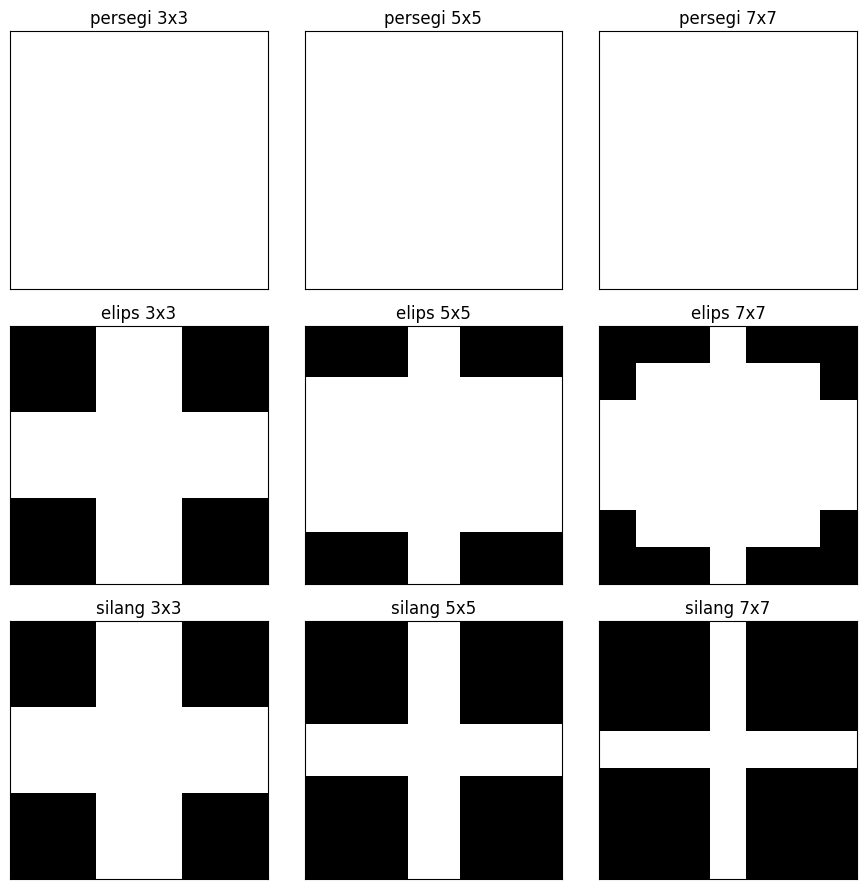

In [9]:
fig, ax = plt.subplots(3, 3, figsize=(9, 9))
for i, (nb, kb) in enumerate(bentuk.items()):
    for j, uk in enumerate([3, 5, 7]):
        se = SE(uk, kb)
        ax[i, j].imshow(se * 255, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
        ax[i, j].set_title(f"{nb} {uk}x{uk}")
        ax[i, j].set_xticks([])
        ax[i, j].set_yticks([])
        ax[i, j].set_facecolor("black")
        for spine in ax[i, j].spines.values():
            spine.set_visible(True)
            spine.set_color("black")
plt.tight_layout()
plt.savefig("../hasil/p6_panel_se.png", dpi=150)
plt.show()

In [ ]:
# KODE 4.1

konektivitas 4: 12 komponen
konektivitas 8: 12 komponen
    label  luas_px  luas_mm2  keliling_px  kebulatan  rasio_aspek   cx   cy
0       1       26      4.98         18.5       0.96         1.87  152  209
1       2      253     48.43         56.6       0.99         1.06  340  214
2       3       17      3.25         13.7       1.15         1.25  165  214
3       4        1      0.19          0.0       0.00         0.00  169  215
4       5       26      4.98         17.1       1.12         1.00  173  216
5       6       80     15.31         43.2       0.54         3.55  187  221
6       7        1      0.19          0.0       0.00         0.00  178  218
7       8     2314    442.91        705.3       0.06        10.81  373  285
8       9      200     38.28         50.6       0.98         1.14  335  239
9      10      539    103.17         85.3       0.93         1.00  373  259
10     11      327     62.59         66.5       0.93         1.05  301  319
11     12      549    105.08    

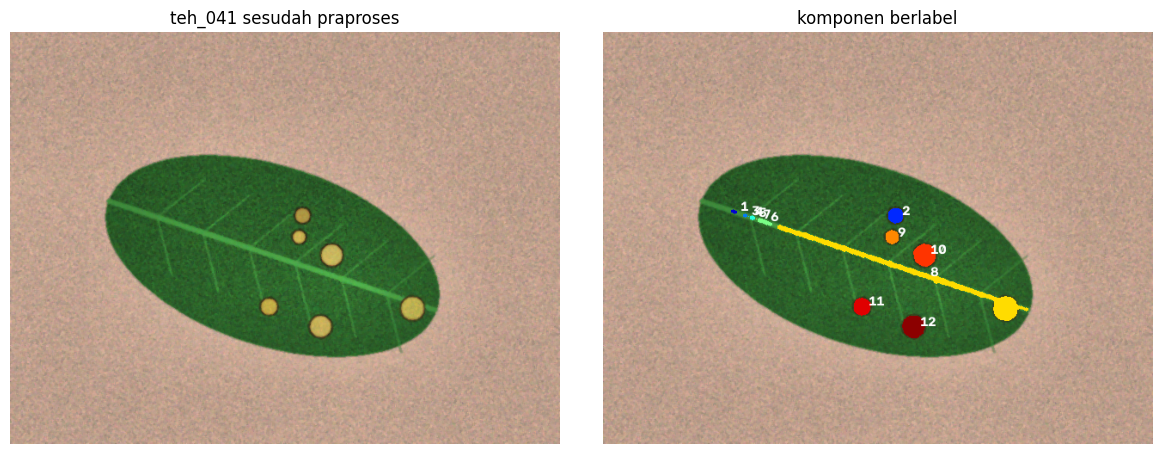

In [11]:
MM_PER_PX = 0.4375                # dari lembar hitung P2: Z = 200 mm, lebar kerja 640 px

def ukur_komponen(m, konek=8):
    n, lbl, st, cen = cv2.connectedComponentsWithStats((m > 0).astype(np.uint8), connectivity=konek)
    baris = []
    for i in range(1, n):
        kontur, _ = cv2.findContours((lbl == i).astype(np.uint8), cv2.RETR_EXTERNAL,
                                      cv2.CHAIN_APPROX_NONE)
        A = int(st[i, cv2.CC_STAT_AREA])
        keliling = cv2.arcLength(kontur[0], True)
        kebulatan = 0.0 if keliling == 0 else 4 * np.pi * A / keliling ** 2
        w, h = cv2.minAreaRect(kontur[0])[1]
        rasio = max(w, h) / max(min(w, h), 1)
        baris.append([i, A, round(A * MM_PER_PX ** 2, 2), round(keliling, 1), round(kebulatan, 2),
                      round(rasio, 2), int(cen[i][0]), int(cen[i][1])])
    kolom = ["label", "luas_px", "luas_mm2", "keliling_px", "kebulatan", "rasio_aspek", "cx", "cy"]
    return pd.DataFrame(baris, columns=kolom), lbl



img, md, mb = muat("teh_041.png")
pra_ = praproses(img, PARAM)
m_daun = mask_daun_awal(pra_)
bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun), cv2.MORPH_OPEN, SE(5)),
                          cv2.MORPH_CLOSE, SE(5))
for konek in [4, 8]:
    print(f"konektivitas {konek}: {jumlah_komponen(bersih, konek)} komponen")
tabel_kom, lbl = ukur_komponen(bersih)
print(tabel_kom)

warna = cv2.applyColorMap((lbl * (255 // max(lbl.max(), 1))).astype(np.uint8), cv2.COLORMAP_JET)
warna[lbl == 0] = pra_[lbl == 0]
for _, r in tabel_kom.iterrows():
    cv2.putText(warna, str(int(r.label)), (int(r.cx) + 8, int(r.cy)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 2)
tampil([pra_, warna], ["teh_041 sesudah praproses", "komponen berlabel"], ukuran=(12, 4.5))

In [ ]:
# KODE 4.2

In [12]:
def saring(m, luas_min=20, bulat_min=0.5, rasio_maks=1.8):
    tabel_k, lbl = ukur_komponen(m)
    lolos = tabel_k[(tabel_k.luas_px >= luas_min) & (tabel_k.kebulatan >= bulat_min)
                    & (tabel_k.rasio_aspek <= rasio_maks)]
    return (np.isin(lbl, lolos.label.values) * 255).astype(np.uint8), lolos

aturan = {"tanpa saring": (0, 0, 99), "luas >= 20": (20, 0, 99),
          "luas + kebulatan": (20, 0.5, 99), "luas + kebulatan + rasio": (20, 0.5, 1.8)}
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun), cv2.MORPH_OPEN, SE(5)),
                              cv2.MORPH_CLOSE, SE(5))
    for nm, (a, b, r) in aturan.items():
        f, _ = saring(bersih, a, b, r)
        baris.append([d.kelas, nm, jumlah_komponen(f), jumlah_komponen(mb)])
uji = pd.DataFrame(baris, columns=["kelas", "aturan", "jumlah", "acuan"])
uji["galat"] = (uji.jumlah - uji.acuan).abs()
print(uji.pivot_table(index="aturan", columns="kelas", values="galat").round(2))
print("Daun sehat yang masih memiliki bercak palsu:")
print(uji[uji.kelas == "sehat"].assign(palsu=lambda t: t.jumlah > 0).groupby("aturan").palsu.sum())

kelas                     berat  ringan  sehat
aturan                                        
luas + kebulatan           1.45    1.05    1.2
luas + kebulatan + rasio   1.15    0.70    0.6
luas >= 20                 1.65    1.60    2.2
tanpa saring               2.15    2.15    3.0
Daun sehat yang masih memiliki bercak palsu:
aturan
luas + kebulatan            13
luas + kebulatan + rasio     9
luas >= 20                  14
tanpa saring                14
Name: palsu, dtype: int64


In [ ]:
# LANGKAH 4.4

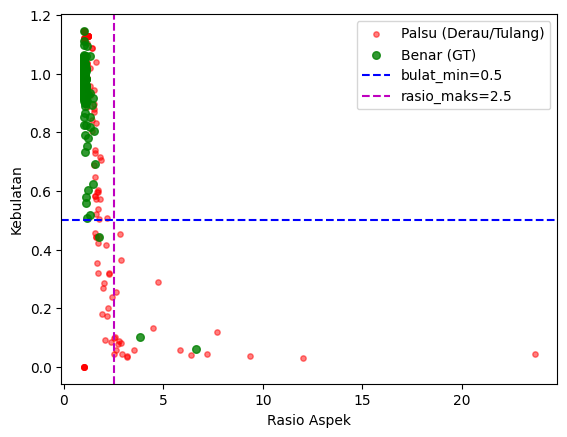

In [13]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2

f_benar, f_palsu = [], []

for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra = praproses(img, PARAM)
    b = cv2.morphologyEx(bercak_awal(pra, md, k=4), cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5,5)))
    b = cv2.morphologyEx(b, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5,5)))

    n, lbl, st, _ = cv2.connectedComponentsWithStats(b, 8)
    for i in range(1, n):
        luas = st[i, cv2.CC_STAT_AREA]
        cnt, _ = cv2.findContours((lbl == i).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if cnt:
            kel = cv2.arcLength(cnt[0], True)
            bulat = (4 * np.pi * luas) / (kel**2) if kel > 0 else 0
            x, y, w, h = cv2.boundingRect(cnt[0])
            rasio = max(w, h) / min(w, h) if min(w, h) > 0 else 1.0

            is_gt = np.sum(np.logical_and(lbl == i, mb > 0)) / luas > 0.5
            (f_benar if is_gt else f_palsu).append([luas, bulat, rasio])

df_b, df_p = pd.DataFrame(f_benar, columns=["l","b","r"]), pd.DataFrame(f_palsu, columns=["l","b","r"])

plt.scatter(df_p["r"], df_p["b"], c="red", s=15, alpha=0.5, label="Palsu (Derau/Tulang)")
plt.scatter(df_b["r"], df_b["b"], c="green", s=30, alpha=0.8, label="Benar (GT)")
plt.axhline(0.5, color="b", ls="--", label="bulat_min=0.5")
plt.axvline(2.5, color="m", ls="--", label="rasio_maks=2.5")
plt.xlabel("Rasio Aspek"); plt.ylabel("Kebulatan"); plt.legend(); plt.show()

In [ ]:
# KODE 5.1

In [14]:
%%writefile ../src/bercak.py
"""bercak.py: analisis bercak SIMUTEH (dipakai ulang mulai P7)."""
import json
import cv2
import numpy as np
from utils_tepi import mask_daun_awal, bercak_awal

PARAM_BERCAK = {
    "kanal": 2,           # kanal terpilih (2 = R)
    "k": 4.0,             # ambang median + k x MAD
    "se_bentuk": "elips", # "elips", "persegi", "silang"
    "se_open": 5,         # ukuran SE opening (0 = tidak dipakai)
    "se_close": 5,        # ukuran SE closing (0 = tidak dipakai)
    "luas_min": 20,       # piksel
    "bulat_min": 0.5,
    "rasio_maks": 1.8,
    "batas_ringan": 0.1,  # persen bercak minimum kelas Ringan
    "batas_berat": 2.0,   # persen bercak minimum kelas Berat
    "mm_per_px": 0.4375,
}
_BENTUK = {"elips": cv2.MORPH_ELLIPSE, "persegi": cv2.MORPH_RECT, "silang": cv2.MORPH_CROSS}


def _se(p, uk):
    return cv2.getStructuringElement(_BENTUK[p["se_bentuk"]], (uk, uk))


def bersihkan(biner, p):
    """Opening membuang titik derau dan potongan tipis; closing menutup celah."""
    if p["se_open"] > 0:
        biner = cv2.morphologyEx(biner, cv2.MORPH_OPEN, _se(p, p["se_open"]))
    if p["se_close"] > 0:
        biner = cv2.morphologyEx(biner, cv2.MORPH_CLOSE, _se(p, p["se_close"]))
    return biner


def ukur_dan_saring(biner, p):
    """Mengembalikan mask bercak tersaring dan daftar ukuran setiap bercak."""
    n, lbl, st, cen = cv2.connectedComponentsWithStats((biner > 0).astype(np.uint8), connectivity=8)
    keluar, daftar = np.zeros_like(biner), []
    for i in range(1, n):
        kontur, _ = cv2.findContours((lbl == i).astype(np.uint8), cv2.RETR_EXTERNAL,
                                     cv2.CHAIN_APPROX_NONE)
        A = int(st[i, cv2.CC_STAT_AREA])
        keliling = cv2.arcLength(kontur[0], True)
        kebulatan = 0.0 if keliling == 0 else 4 * np.pi * A / keliling ** 2
        w, h = cv2.minAreaRect(kontur[0])[1]
        rasio = max(w, h) / max(min(w, h), 1)
        if A >= p["luas_min"] and kebulatan >= p["bulat_min"] and rasio <= p["rasio_maks"]:
            keluar[lbl == i] = 255
            daftar.append({"label": i, "luas_px": A, "luas_mm2": round(A * p["mm_per_px"] ** 2, 2),
                           "keliling_px": round(float(keliling), 1), "kebulatan": round(float(kebulatan), 2),
                           "rasio_aspek": round(float(rasio), 2),
                           "cx": int(cen[i][0]), "cy": int(cen[i][1])})
    return keluar, daftar


def analisis_daun(img_praproses, p=None):
    """Masukan: citra BGR hasil praproses. Keluaran: kamus hasil analisis."""
    p = {**PARAM_BERCAK, **(p or {})}
    m_daun = mask_daun_awal(img_praproses)
    biner = bercak_awal(img_praproses, m_daun, kanal=p["kanal"], k=p["k"])
    m_bercak, daftar = ukur_dan_saring(bersihkan(biner, p), p)
    luas_daun = int((m_daun > 0).sum())
    luas_bercak = int((m_bercak > 0).sum())
    persen = luas_bercak / luas_daun * 100 if luas_daun > 0 else 0.0
    if persen < p["batas_ringan"]:
        kelas = "Sehat"
    elif persen < p["batas_berat"]:
        kelas = "Ringan"
    else:
        kelas = "Berat"
    return {"mask_daun": m_daun, "mask_bercak": m_bercak, "jumlah_bercak": len(daftar),
             "persen_bercak": round(float(persen), 3), "kelas": kelas, "bercak": daftar}


def simpan_param(p, path="../hasil/param_bercak.json"):
    with open(path, "w") as f:
        json.dump({**PARAM_BERCAK, **p}, f, indent=2)

Overwriting ../src/bercak.py


In [15]:
from bercak import analisis_daun
h = analisis_daun(praproses(muat("teh_041.png")[0], PARAM))
print(h["jumlah_bercak"], h["persen_bercak"], h["kelas"])

6 2.883 Berat


In [ ]:
# LANGKAH 5.2

Galat absolut rerata persen bercak: 0.66
Korelasi persen prediksi vs acuan : 0.943
Akurasi kelas                                  : 0.85
prediksi       Berat  Ringan  Sehat
acuan                              
Bercak Berat      18       2      0
Bercak Ringan      0      13      7
Sehat              0       0     20
kondisi
bayangan          0.92
gelap             0.92
kontras_rendah    0.75
normal            1.00
terang            0.67
Name: benar, dtype: float64


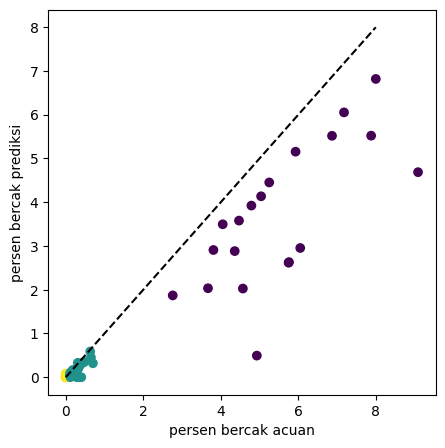

In [16]:
import importlib, bercak
importlib.reload(bercak)
PB = {}                                                           # ubah parameter sesuai temuan Anda
bercak.simpan_param(PB)

baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    h = bercak.analisis_daun(praproses(img, PARAM), PB)
    baris.append([d.nama_file, d.kelas, d.kondisi_cahaya, d.persen_bercak, h["persen_bercak"],
                  jumlah_komponen(mb), h["jumlah_bercak"], h["kelas"]])
ev = pd.DataFrame(baris, columns=["nama", "kelas", "kondisi", "persen_acuan", "persen_prediksi",
                                  "jumlah_acuan", "jumlah_prediksi", "kelas_prediksi"])
ev["kelas_acuan"] = ev.kelas.map({"sehat": "Sehat", "ringan": "Bercak Ringan", "berat": "Bercak Berat"})
ev.to_csv("../hasil/p6_evaluasi_bercak.csv", index=False)

peta = {"Berat": "Bercak Berat", "Ringan": "Bercak Ringan", "Sehat": "Sehat"}
print("Galat absolut rerata persen bercak:", (ev.persen_prediksi - ev.persen_acuan).abs().mean().round(3))
print("Korelasi persen prediksi vs acuan :", ev[["persen_prediksi", "persen_acuan"]].corr().iloc[0, 1].round(3))
print("Akurasi kelas                                  :", (ev.kelas_prediksi.map(peta) == ev.kelas_acuan).mean().round(3))
print(pd.crosstab(ev.kelas_acuan, ev.kelas_prediksi, rownames=["acuan"], colnames=["prediksi"]))
print(ev.assign(benar=ev.kelas_prediksi.map(peta) == ev.kelas_acuan).groupby("kondisi").benar.mean().round(2))

plt.figure(figsize=(5, 5))
plt.scatter(ev.persen_acuan, ev.persen_prediksi, c=ev.kelas.astype("category").cat.codes)
plt.plot([0, 8], [0, 8], "k--"); plt.xlabel("persen bercak acuan"); plt.ylabel("persen bercak prediksi")
plt.show()

In [ ]:
# LANGKAH 5.3

Total salah kelas: 9


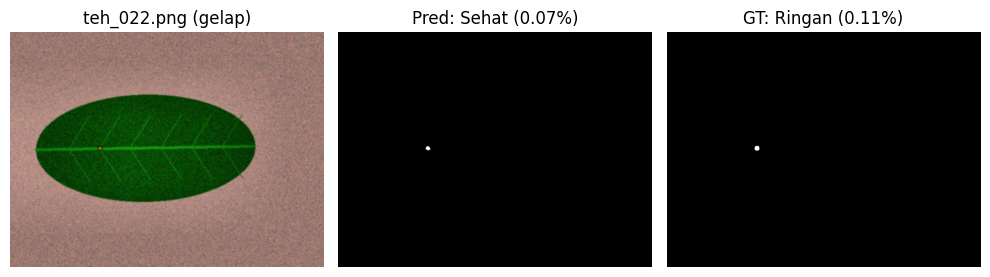

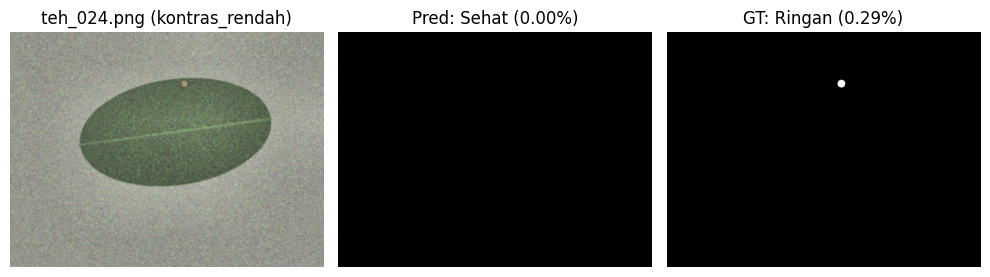

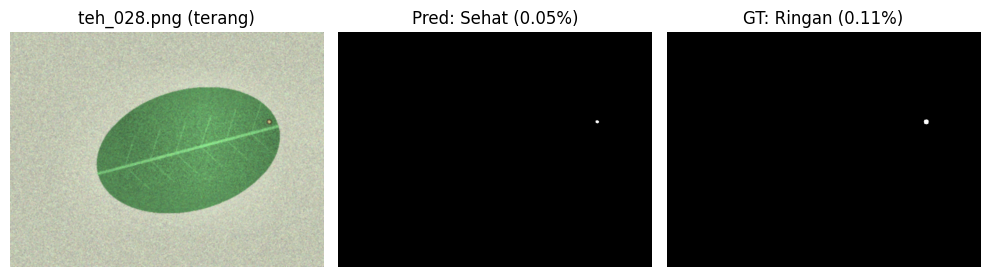

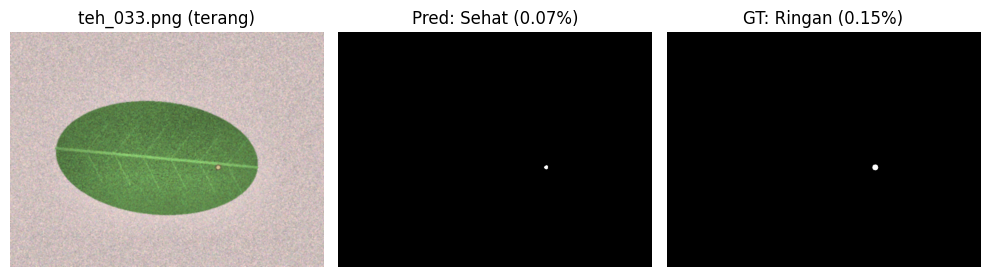

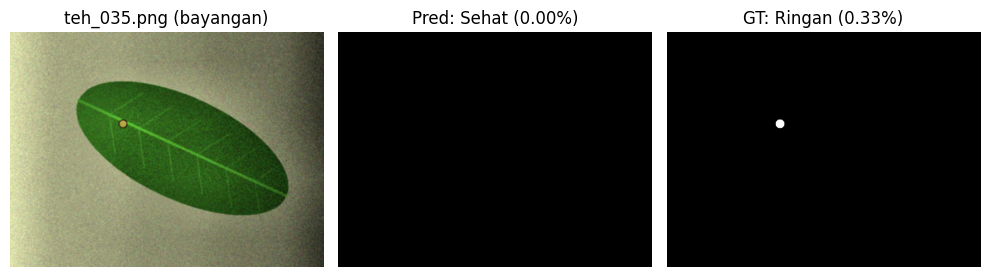

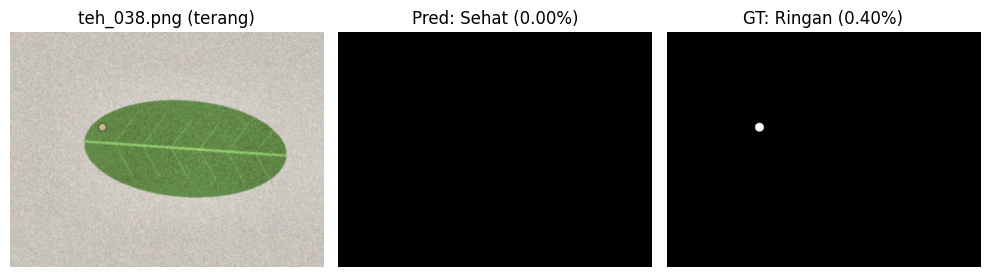

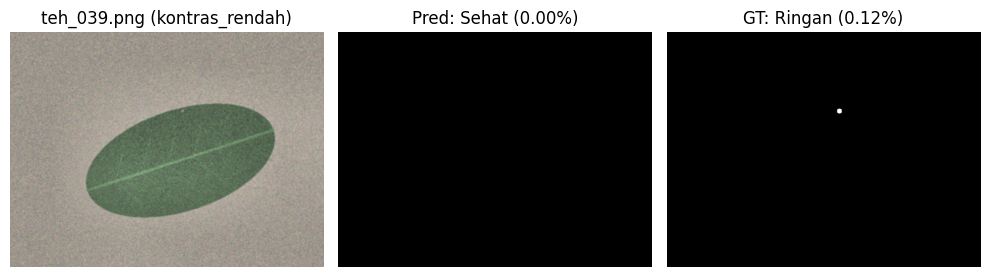

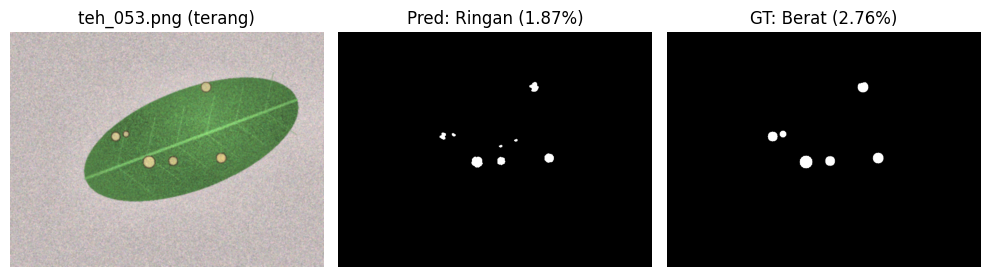

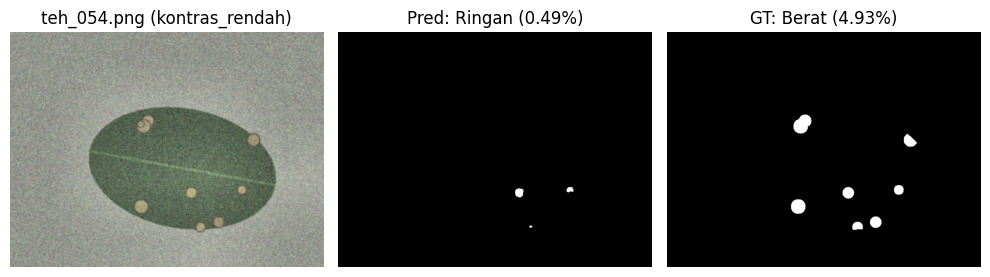

In [20]:
import matplotlib.pyplot as plt, cv2, numpy as np
from bercak import analisis_daun, PARAM_BERCAK

salah = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra = praproses(img, PARAM)

    # Memanggil analisis_daun dengan benar menggunakan modul bercak
    h = analisis_daun(pra, PARAM_BERCAK)
    p_pred = h["persen_bercak"]
    k_pred = h["kelas"]
    mask_h = h["mask_bercak"]

    p_acuan = (np.sum(mb > 0) / np.sum(md > 0)) * 100 if np.sum(md > 0) > 0 else 0
    k_acuan = "Sehat" if p_acuan < 0.1 else ("Ringan" if p_acuan <= 2.0 else "Berat")

    if k_pred != k_acuan:
        salah.append((d.nama_file, d.kondisi_cahaya, pra, mask_h, mb, k_acuan, k_pred, p_acuan, p_pred))

print(f"Total salah kelas: {len(salah)}")

for file, kond, pra, mh, ma, ka, kp, pa, pp in salah:
    fig, ax = plt.subplots(1, 3, figsize=(10, 3))
    ax[0].imshow(cv2.cvtColor(pra, cv2.COLOR_BGR2RGB)); ax[0].set_title(f"{file} ({kond})")
    ax[1].imshow(mh, cmap='gray'); ax[1].set_title(f"Pred: {kp} ({pp:.2f}%)")
    ax[2].imshow(ma, cmap='gray'); ax[2].set_title(f"GT: {ka} ({pa:.2f}%)")
    for a in ax: a.axis('off')
    plt.tight_layout(); plt.show()